# K-nearest neighbors: from a picture to a prediction

**Start with [the beginner guide](KNN_Beginner_Guide.pdf).** Then run this notebook from top to bottom. Stop at the prediction questions before revealing the output.

**You will learn to:** calculate distances; explain neighbor voting; distinguish fitting from prediction; scale without leaking data; select k using validation; and interpret model errors.

We compare KNN, logistic regression, a shallow decision tree, and a majority baseline on the same two Project 2 features. **Classroom only: this historical breast-cancer exercise is not a medical diagnostic tool.** Allow 60-90 minutes. No dataset download is required.

If imports fail, install `numpy`, `matplotlib`, and `scikit-learn` using the parent `assignment_requirements.txt` in your selected kernel environment.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn import __version__ as sklearn_version
from sklearn.datasets import load_breast_cancer, load_iris
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42
FEATURES = ['mean radius', 'mean texture']
CLASS_NAMES = ['benign (0)', 'malignant (1)']
COLORS = ['#187a78', '#c65324']
print('scikit-learn:', sklearn_version)

scikit-learn: 1.8.0


## 1. Start with real Iris flowers

The famous **Iris dataset** is bundled with scikit-learn as `load_iris()`. It contains 150 flowers, four measurements in centimeters, and three species: **setosa, versicolor, virginica**. We use only **petal length** and **petal width**. A petal is a colored part of a flower: length runs from base to tip; width runs across its widest part. See the measurement sketch in the PDF.

**Inputs:** two physical sizes in centimeters. For flower A, 4.6 means **a petal 4.6 cm long**; 1.5 means **1.5 cm wide**. They are not scores or ratings.

**Output (target or class label):** the species name. Scikit-learn codes the full dataset as 0 = setosa, 1 = versicolor, 2 = virginica. Codes are category names, not measurements to average or include in distance.

| Flower | Petal length (cm) | Petal width (cm) | Known species | Dataset row ID |
|---|---:|---:|---|---:|
| A | 4.6 | 1.5 | versicolor | 54 |
| B | 4.5 | 1.7 | virginica | 106 |
| C | 4.7 | 1.4 | versicolor | 50 |
| D | 5.0 | 1.5 | virginica | 119 |
| E | 5.1 | 1.5 | virginica | 133 |

These five real references were deliberately selected for manageable arithmetic; they contain **two of the three species**. Row IDs are zero-based positions, not features. We are not evaluating a classifier on all 150 flowers.

The query flower is row 51: **petal length 4.5 cm, width 1.5 cm**. It is not among the references. Hide its species during prediction, then check it afterward. The most common species among k nearest references wins. **k counts neighbors, not classes.** This example uses raw centimeters; the main experiment later uses scaling.

**Before running:** visually guess the three nearest reference flowers and the predicted species.

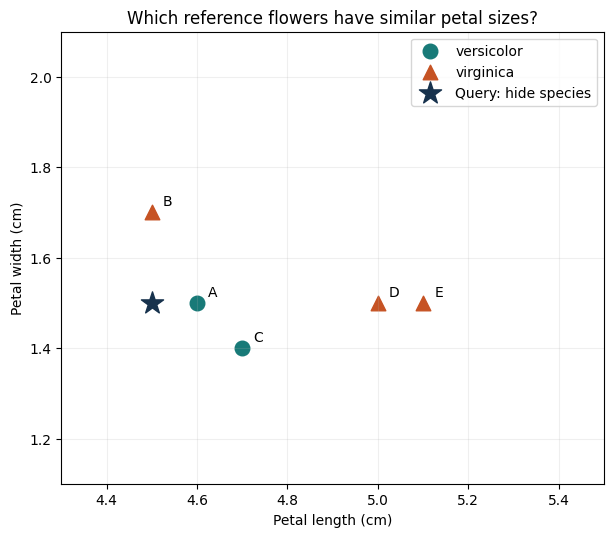

In [2]:
iris = load_iris()
reference_rows = np.array([54, 106, 50, 119, 133])
query_row = 51
assert query_row not in reference_rows
toy_X = iris.data[reference_rows, 2:]
toy_y = iris.target[reference_rows]
flower_names = np.array(list('ABCDE'))
query_flower = iris.data[[query_row], 2:]
fig, ax = plt.subplots(figsize=(7, 6))
for label, marker in [(1, 'o'), (2, '^')]:
    ax.scatter(*toy_X[toy_y == label].T, c=COLORS[label - 1], marker=marker, s=110, label=iris.target_names[label])
for name, point in zip(flower_names, toy_X):
    ax.annotate(name, point, xytext=(8, 5), textcoords='offset points')
ax.scatter(*query_flower[0], marker='*', s=280, c='#17324d', label='Query: hide species')
ax.set(xlim=(4.3, 5.5), ylim=(1.1, 2.1), xlabel='Petal length (cm)', ylabel='Petal width (cm)', title='Which reference flowers have similar petal sizes?')
ax.set_aspect('equal')
ax.grid(alpha=0.2)
ax.legend()
plt.show()

### Watch the math first: distance, then voting

**Euclidean distance** is straight-line distance in the measurement plane. The query flower is (4.5, 1.5). The symbols x and y mean a reference flower's petal length and width in centimeters; d means distance. Species is not an input to this calculation.

$$d = \sqrt{(x-4.5)^2 + (y-1.5)^2}$$

A square multiplies a number by itself. A square root reverses squaring: the square root of 0.01 is 0.1 because 0.1 times 0.1 equals 0.01. Keep full precision when sorting; round only for display.

**Worked example A, at (4.6, 1.5):**
1. Subtract: 4.6 minus 4.5 is 0.1; 1.5 minus 1.5 is 0.
2. Square: 0.1 squared is 0.01; zero squared is 0.
3. Add: 0.01 plus 0 is 0.01.
4. Take the square root: A is 0.1 cm away in the length-width plane.

$$d_A = \sqrt{(4.6-4.5)^2 + (1.5-1.5)^2} = \sqrt{0.1^2+0^2} = \sqrt{0.01} = 0.1$$

**Worked example C, at (4.7, 1.4):**
1. Subtract: 4.7 minus 4.5 is 0.2; 1.4 minus 1.5 is -0.1.
2. Square: 0.2 squared is 0.04; (-0.1) squared is 0.01. The negative difference becomes positive.
3. Add: 0.04 plus 0.01 is 0.05.
4. Take the square root: approximately 0.224 cm. A is closer than C.

$$d_C = \sqrt{(4.7-4.5)^2 + (1.4-1.5)^2} = \sqrt{0.04+0.01} = \sqrt{0.05} \approx 0.224$$

**Worked vote:** sorted distances are A = 0.100, B = 0.200, C = 0.224, D = 0.500, E = 0.600 cm (display rounded). For k = 3 choose A, B, C: versicolor, virginica, versicolor. Two versicolor votes beat one virginica vote, so predict versicolor.

$$\text{Versicolor vote fraction} = \frac{2}{3} \approx 0.667 = 66.7\%$$

That fraction describes the selected neighbors, not a guaranteed calibrated probability that the flower is versicolor.

### Now your turn

Calculate distances for **B at (4.5, 1.7)** and **D at (5.0, 1.5)**, showing the four steps. Then predict the species for **k = 1** and **k = 5**. Does the prediction change from the worked k = 3 result? Try before running the answer cell.

In [3]:
distances = np.linalg.norm(toy_X - query_flower[0], axis=1)
nearest_order = np.argsort(distances)
assert np.allclose(distances, [0.1, 0.2, np.sqrt(0.05), 0.5, 0.6])
print('B: subtract (0, 0.2); square (0, 0.04); add 0.04; square root = 0.2 cm.')
print('D: subtract (0.5, 0); square (0.25, 0); add 0.25; square root = 0.5 cm.')
for i in nearest_order:
    print(f'{flower_names[i]} (dataset row {reference_rows[i]}): distance={distances[i]:.3f} cm, species={iris.target_names[toy_y[i]]}')

for k, expected in [(1, 1), (3, 1), (5, 2)]:
    toy_model = KNeighborsClassifier(n_neighbors=k, weights='uniform', metric='euclidean')
    toy_model.fit(toy_X, toy_y)
    prediction = int(toy_model.predict(query_flower)[0])
    neighbor_distances, neighbor_indices = toy_model.kneighbors(query_flower)
    votes = toy_y[neighbor_indices[0]]
    versicolor_fraction = toy_model.predict_proba(query_flower)[0, np.flatnonzero(toy_model.classes_ == 1)[0]]
    assert prediction == expected
    assert np.isclose(versicolor_fraction, np.mean(votes == 1))
    print(f'k={k}: voters={flower_names[neighbor_indices[0]].tolist()}, species={iris.target_names[votes].tolist()}, prediction={iris.target_names[prediction]}, versicolor fraction={versicolor_fraction:.3f}')
print('Answer: k=1 and k=3 predict versicolor; k=5 predicts virginica.')
print('Reveal the hidden species:', iris.target_names[iris.target[query_row]])
print('Changing k changes the voters. A majority vote can still be wrong.')

B: subtract (0, 0.2); square (0, 0.04); add 0.04; square root = 0.2 cm.
D: subtract (0.5, 0); square (0.25, 0); add 0.25; square root = 0.5 cm.
A (dataset row 54): distance=0.100 cm, species=versicolor
B (dataset row 106): distance=0.200 cm, species=virginica
C (dataset row 50): distance=0.224 cm, species=versicolor
D (dataset row 119): distance=0.500 cm, species=virginica
E (dataset row 133): distance=0.600 cm, species=virginica
k=1: voters=['A'], species=['versicolor'], prediction=versicolor, versicolor fraction=1.000


k=3: voters=['A', 'B', 'C'], species=['versicolor', 'virginica', 'versicolor'], prediction=versicolor, versicolor fraction=0.667
k=5: voters=['A', 'B', 'C', 'D', 'E'], species=['versicolor', 'virginica', 'versicolor', 'virginica', 'virginica'], prediction=virginica, versicolor fraction=0.400
Answer: k=1 and k=3 predict versicolor; k=5 predicts virginica.
Reveal the hidden species: versicolor
Changing k changes the voters. A majority vote can still be wrong.


## 2. What is the model, and why does scaling matter?

- **Logistic regression** learns coefficients and an intercept.
- **Decision trees** learn questions and leaf predictions.
- **Basic KNN** retains training features and their labels, along with settings such as k, distance metric, and voting rule. A library may build a search structure to find neighbors efficiently.

`fit` prepares this stored reference information. `predict` finds neighbors for a new row and votes. The new row's true label is not available to the predictor.

The Iris hand example used raw centimeters to keep the arithmetic visible. Having the same units does not guarantee equal spreads or equally useful features. In other data, different units and large numerical ranges can also dominate distance. **StandardScaler** uses training means and standard deviations separately for each feature:

$$z = \frac{\text{value} - \text{training mean}}{\text{training standard deviation}}$$

**Worked scaling example (separate invented numbers, not course dataset statistics):** suppose feature 1 has training mean 10 and standard deviation 2; feature 2 has training mean 20 and standard deviation 5. A new raw row is (14, 25).

$$z_1 = \frac{14-10}{2} = \frac{4}{2} = 2 \qquad z_2 = \frac{25-20}{5} = \frac{5}{5} = 1$$

The raw row becomes (2, 1): two standard deviations above the first training mean, one above the second. Fit the scaler on training rows only and use those saved summaries for new rows. A pipeline applies this automatically. Scaling does not guarantee useful distances; feature choice still matters.

With uniform weights, `predict_proba` reports the fraction of neighbors in each class. These fractions are not necessarily calibrated probabilities. Odd k helps avoid binary vote ties, but equal-distance ties at the neighbor cutoff can still occur. With three or more species, odd k can still produce tied class counts; our small subset uses only two species.

### Switch datasets for the main comparison

The Iris illustration is complete. From the next cell onward, we return to the **breast-cancer dataset** so logistic regression, the tree, and KNN use the same course data. The features and labels change: **mean radius, mean texture; 0 = benign, 1 = malignant**. Iris species codes are not reused. The small Iris subset is not part of this main experiment.

In [4]:
data = load_breast_cancer()
feature_indices = [list(data.feature_names).index(name) for name in FEATURES]
X = data.data[:, feature_indices]
# Original sklearn labels are reversed relative to our course convention.
y = (data.target == 0).astype(int)
if not np.isfinite(X).all():
    raise ValueError('Unexpected missing or infinite values in the selected course features.')
print('Shape:', X.shape, '| feature order:', FEATURES)
print('Missing values:', np.isnan(X).sum(axis=0))
print('Class counts (0 = benign, 1 = malignant):', np.bincount(y))

indices = np.arange(len(y))
train_val_idx, test_idx = train_test_split(indices, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
train_idx, validation_idx = train_test_split(train_val_idx, test_size=0.25, stratify=y[train_val_idx], random_state=RANDOM_STATE)
assert not (set(train_idx) & set(validation_idx) or set(train_idx) & set(test_idx) or set(validation_idx) & set(test_idx))
assert len(np.unique(np.concatenate([train_idx, validation_idx, test_idx]))) == len(y)
X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[validation_idx], y[validation_idx]
X_train_val, y_train_val = X[train_val_idx], y[train_val_idx]
X_test, y_test = X[test_idx], y[test_idx]
for name, labels in [('training', y_train), ('validation', y_val), ('test', y_test)]:
    print(f'{name}: {len(labels)} rows, class counts={np.bincount(labels).tolist()}')

Shape: (569, 2) | feature order: ['mean radius', 'mean texture']
Missing values: [0 0]
Class counts (0 = benign, 1 = malignant): [357 212]
training: 341 rows, class counts=[214, 127]
validation: 114 rows, class counts=[71, 43]
test: 114 rows, class counts=[72, 42]


## 3. Set up a fair, limited comparison

These are the same **569 rows, mean radius, mean texture, and 0/1 label mapping** used in the earlier course lessons. The split matches the decision-tree notebook: 60% training, 20% validation, 20% test.

We will select KNN's k by **validation accuracy**, with smaller k breaking ties. This is an instructional choice, not a clinical objective. Other settings remain fixed: logistic regression uses its default C = 1; the tree has depth 2. We do not claim that all models received equal tuning or that the winner is universally best.

Our majority baseline always predicts the most frequent training class. KNN and logistic regression get training-fitted scaling; the tree uses the original features. No test results may be used to choose k.

In [5]:
def make_knn(k):
    return make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k, weights='uniform', metric='euclidean'))

def summarize(name, model, features, labels):
    predictions = model.predict(features)
    metrics = {
        'model': name,
        'accuracy': accuracy_score(labels, predictions),
        'precision': precision_score(labels, predictions, zero_division=0),
        'recall': recall_score(labels, predictions, zero_division=0),
        'F1': f1_score(labels, predictions, zero_division=0),
    }
    print(f"{name:24s} accuracy={metrics['accuracy']:.3f} precision={metrics['precision']:.3f} recall={metrics['recall']:.3f} F1={metrics['F1']:.3f}")
    if not np.any(predictions == 1):
        print('  No class-1 predictions: precision is undefined and displayed as 0; recall is 0.')
    return metrics

fixed_models = {
    'Majority baseline': DummyClassifier(strategy='most_frequent'),
    'Logistic regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    'Decision tree (depth 2)': DecisionTreeClassifier(max_depth=2, random_state=RANDOM_STATE),
}
for name, model in fixed_models.items():
    model.fit(X_train, y_train)
    summarize(name, model, X_val, y_val)
initial_knn = make_knn(5).fit(X_train, y_train)
summarize('KNN (initial k=5)', initial_knn, X_val, y_val)
assert np.allclose(initial_knn.named_steps['standardscaler'].mean_, X_train.mean(axis=0))
print('Saved training means:', initial_knn.named_steps['standardscaler'].mean_)

Majority baseline        accuracy=0.623 precision=0.000 recall=0.000 F1=0.000
  No class-1 predictions: precision is undefined and displayed as 0; recall is 0.
Logistic regression      accuracy=0.877 precision=0.872 recall=0.791 F1=0.829
Decision tree (depth 2)  accuracy=0.877 precision=0.968 recall=0.698 F1=0.811
KNN (initial k=5)        accuracy=0.860 precision=0.886 recall=0.721 F1=0.795
Saved training means: [14.16341935 19.42876833]


### Choose k and inspect overfitting

**Before running:** predict what k = 1 will do on the training rows. Each training row can be its own nearest neighbor when we predict on the training data! That high score does not measure performance on new rows.

A large training/validation gap is a warning, not proof by itself. Very large k may underfit by smoothing away local patterns. The curve need not change monotonically. Our candidate list is fixed before we see the test results.

k= 1: training accuracy=1.000, validation accuracy=0.807
k= 3: training accuracy=0.924, validation accuracy=0.868
k= 5: training accuracy=0.909, validation accuracy=0.860
k= 7: training accuracy=0.906, validation accuracy=0.895
k= 9: training accuracy=0.894, validation accuracy=0.895
k=15: training accuracy=0.906, validation accuracy=0.886
k=25: training accuracy=0.909, validation accuracy=0.886
k=51: training accuracy=0.900, validation accuracy=0.886
Selected k from validation accuracy: 7


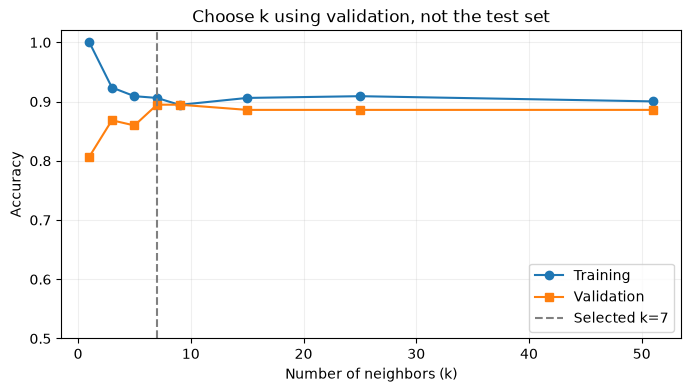

In [6]:
k_values = [1, 3, 5, 7, 9, 15, 25, 51]
knn_candidates = {}
selection_rows = []
for k in k_values:
    candidate = make_knn(k).fit(X_train, y_train)
    knn_candidates[k] = candidate
    train_accuracy = candidate.score(X_train, y_train)
    val_accuracy = candidate.score(X_val, y_val)
    selection_rows.append((k, train_accuracy, val_accuracy))
    print(f'k={k:2d}: training accuracy={train_accuracy:.3f}, validation accuracy={val_accuracy:.3f}')
best_k = max(selection_rows, key=lambda row: (row[2], -row[0]))[0]
selected_knn = knn_candidates[best_k]
assert best_k in k_values
print('Selected k from validation accuracy:', best_k)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(k_values, [row[1] for row in selection_rows], 'o-', label='Training')
ax.plot(k_values, [row[2] for row in selection_rows], 's-', label='Validation')
ax.axvline(best_k, color='gray', linestyle='--', label=f'Selected k={best_k}')
ax.set(xlabel='Number of neighbors (k)', ylabel='Accuracy', ylim=(0.5, 1.02), title='Choose k using validation, not the test set')
ax.grid(alpha=0.2)
ax.legend()
plt.show()

## 4. Explain one real-data prediction

We inspect the **first validation row**, not a hand-picked success. Its true label is used only to check the prediction. The search uses **scaled training features**. The plot uses scaled coordinates too, so its distances agree with the model.

**Look for:** which rows voted, their known labels, the majority label, and whether the prediction matched reality. A neighbor is similar in the two selected measurements; that does not imply the people or their outcomes are otherwise similar.

New raw row: [11.68 16.17] | actual label: 0
Training dataset row 422: scaled distance=0.040, label=0
Training dataset row 146: scaled distance=0.100, label=1
Training dataset row 136: scaled distance=0.115, label=0
Training dataset row 84: scaled distance=0.149, label=0
Training dataset row 344: scaled distance=0.166, label=0
Training dataset row 189: scaled distance=0.183, label=0
Training dataset row 388: scaled distance=0.192, label=0
Votes by class: [6 1]
Prediction=0, class-1 vote fraction=0.143, correct=True


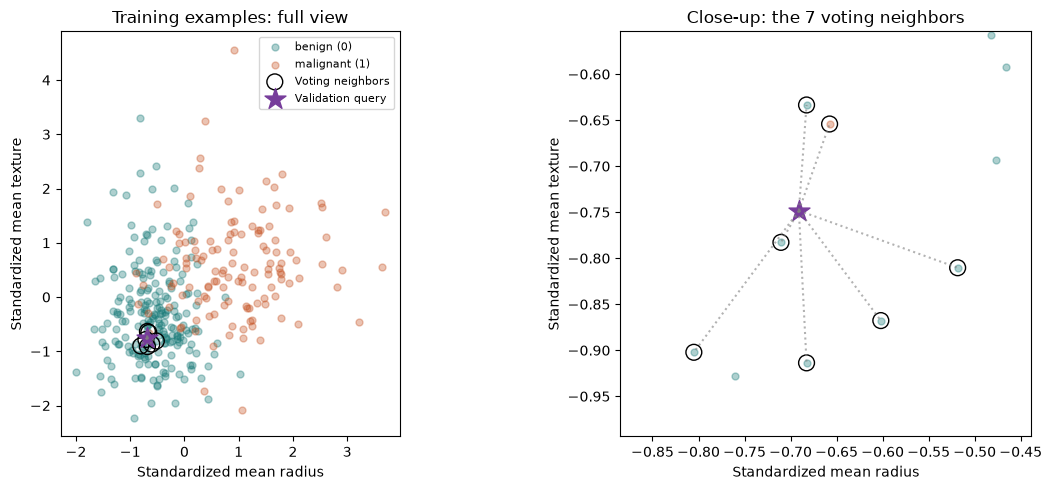

In [7]:
scaler = selected_knn.named_steps['standardscaler']
neighbor_model = selected_knn.named_steps['kneighborsclassifier']
query_raw = X_val[:1]
query_scaled = scaler.transform(query_raw)
train_scaled = scaler.transform(X_train)
neighbor_distances, neighbor_indices = neighbor_model.kneighbors(query_scaled)
voters = neighbor_indices[0]
votes = y_train[voters]
prediction = int(selected_knn.predict(query_raw)[0])
class_1_column = np.flatnonzero(selected_knn.classes_ == 1)[0]
vote_fraction = selected_knn.predict_proba(query_raw)[0, class_1_column]
assert np.isclose(vote_fraction, votes.mean())
assert prediction == int(votes.mean() > 0.5)
print('New raw row:', query_raw[0], '| actual label:', y_val[0])
for distance, local_index in zip(neighbor_distances[0], voters):
    print(f'Training dataset row {train_idx[local_index]}: scaled distance={distance:.3f}, label={y_train[local_index]}')
print('Votes by class:', np.bincount(votes, minlength=2))
print(f'Prediction={prediction}, class-1 vote fraction={vote_fraction:.3f}, correct={prediction == y_val[0]}')
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax in axes:
    for label in [0, 1]:
        ax.scatter(*train_scaled[y_train == label].T, c=COLORS[label], alpha=0.35, s=25, label=CLASS_NAMES[label])
    ax.scatter(*train_scaled[voters].T, facecolors='none', edgecolors='black', s=130, label='Voting neighbors')
    ax.scatter(*query_scaled[0], marker='*', s=250, c='#773d9b', label='Validation query')
    for point in train_scaled[voters]:
        ax.plot([query_scaled[0, 0], point[0]], [query_scaled[0, 1], point[1]], ':', color='gray', alpha=0.6)
    ax.set(xlabel='Standardized mean radius', ylabel='Standardized mean texture')
    ax.set_aspect('equal', adjustable='box')
axes[0].set_title('Training examples: full view')
axes[0].legend(fontsize=8)
zoom_points = np.vstack([train_scaled[voters], query_scaled])
axes[1].set(xlim=(zoom_points[:, 0].min() - 0.08, zoom_points[:, 0].max() + 0.08), ylim=(zoom_points[:, 1].min() - 0.08, zoom_points[:, 1].max() + 0.08), title=f'Close-up: the {best_k} voting neighbors')
fig.tight_layout()
plt.show()

### Compare the shapes of the models

A decision boundary separates regions assigned different labels. Background color below is **predicted class, not confidence**. Dots are training examples. Logistic regression produces a straight-line boundary in these two features; the tree creates axis-aligned regions; KNN follows local neighborhoods.

**Explain:** Which boundary is most irregular? Where do models disagree? Why does a visually attractive boundary not prove better performance? These models are still training-only fits, not the final refits.

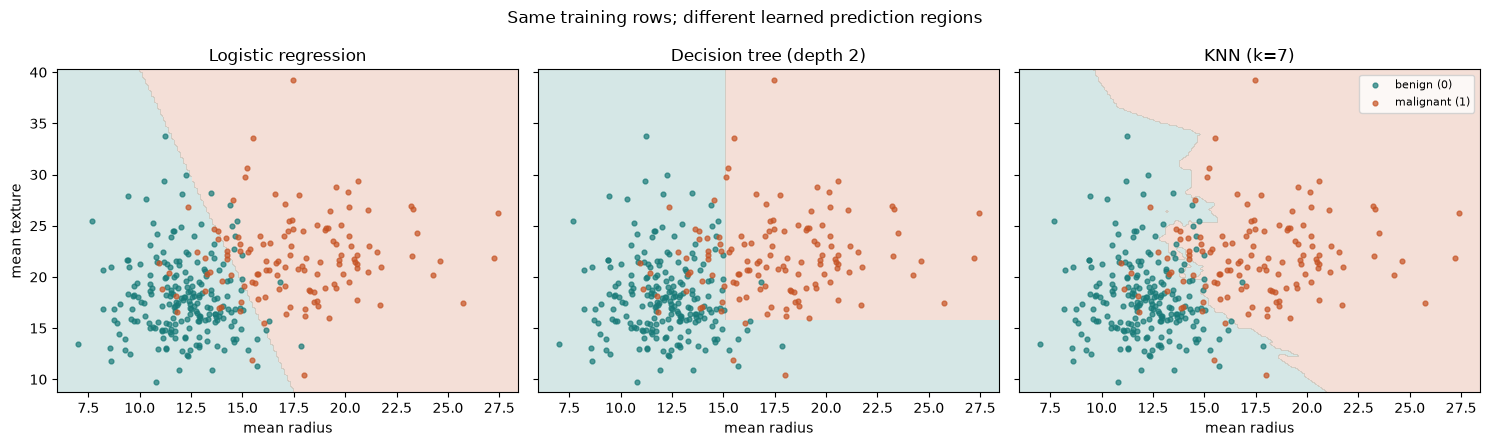

In [8]:
from matplotlib.colors import ListedColormap
x_axis = np.linspace(X_train[:, 0].min() - 1, X_train[:, 0].max() + 1, 160)
y_axis = np.linspace(X_train[:, 1].min() - 1, X_train[:, 1].max() + 1, 160)
xx, yy = np.meshgrid(x_axis, y_axis)
grid = np.column_stack([xx.ravel(), yy.ravel()])
boundary_models = {
    'Logistic regression': fixed_models['Logistic regression'],
    'Decision tree (depth 2)': fixed_models['Decision tree (depth 2)'],
    f'KNN (k={best_k})': selected_knn,
}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)
for ax, (name, model) in zip(axes, boundary_models.items()):
    regions = model.predict(grid).reshape(xx.shape)
    ax.contourf(xx, yy, regions, levels=[-0.5, 0.5, 1.5], cmap=ListedColormap(COLORS), alpha=0.18)
    for label in [0, 1]:
        ax.scatter(*X_train[y_train == label].T, c=COLORS[label], s=12, alpha=0.7, label=CLASS_NAMES[label])
    ax.set(title=name, xlabel=FEATURES[0])
axes[0].set_ylabel(FEATURES[1])
axes[-1].legend(fontsize=8)
fig.suptitle('Same training rows; different learned prediction regions')
fig.tight_layout()
plt.show()

## 5. Missing values do not disappear automatically

Scikit-learn's KNN classifier does **not** accept NaN inputs directly. The real selected dataset has no missing values, so the next cell is a **separate synthetic demonstration**, not a change to our main experiment.

Put `SimpleImputer` before scaling and KNN. It learns replacement values from training rows only, then applies them to new rows. This is ordinary median imputation, **not KNNImputer** (a different estimator). Missingness can carry information or bias, so filling values is not the end of data-quality analysis.

Notice the new row's value 100 does not influence the learned training median.

In [9]:
missing_train = np.array([[1., 10.], [2., np.nan], [3., 30.], [4., 40.]])
missing_labels = np.array([0, 0, 1, 1])
missing_query = np.array([[np.nan, 100.]])
missing_pipeline = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), KNeighborsClassifier(n_neighbors=3))
missing_pipeline.fit(missing_train, missing_labels)
learned_medians = missing_pipeline.named_steps['simpleimputer'].statistics_.copy()
assert np.allclose(learned_medians, [2.5, 30.])
print('Training-only medians:', learned_medians)
print('Imputed query:', missing_pipeline.named_steps['simpleimputer'].transform(missing_query))
print('Synthetic prediction:', missing_pipeline.predict(missing_query))
assert np.array_equal(learned_medians, missing_pipeline.named_steps['simpleimputer'].statistics_)

Training-only medians: [ 2.5 30. ]
Imputed query: [[  2.5 100. ]]
Synthetic prediction: [1]


## 6. Freeze settings, refit, and evaluate once

k is now fixed. Refit **new model objects** using training plus validation rows. Their scalers may now learn from those combined rows because model selection is complete. Test rows still cannot influence fitting.

The final table and confusion matrices all use the same held-out test rows. We do not go back and change k after looking at these results. In a real project, repeated tuning needs stronger cross-validation and a genuinely untouched final evaluation set.

**Metric vocabulary (positive class = malignant, label 1):**
- Accuracy: fraction of all rows correctly classified.
- Precision: among predicted malignant rows, the fraction actually malignant.
- Recall: among actual malignant rows, the fraction detected.
- F1: harmonic mean of precision and recall.
- False negative: actual malignant predicted benign. False positive: actual benign predicted malignant.

All classifiers here use their default prediction rule; we do not tune probability thresholds.

Majority baseline        accuracy=0.632 precision=0.000 recall=0.000 F1=0.000
  No class-1 predictions: precision is undefined and displayed as 0; recall is 0.
Logistic regression      accuracy=0.868 precision=0.886 recall=0.738 F1=0.805
Decision tree (depth 2)  accuracy=0.860 precision=0.933 recall=0.667 F1=0.778
KNN (k=7)                accuracy=0.904 precision=0.970 recall=0.762 F1=0.853


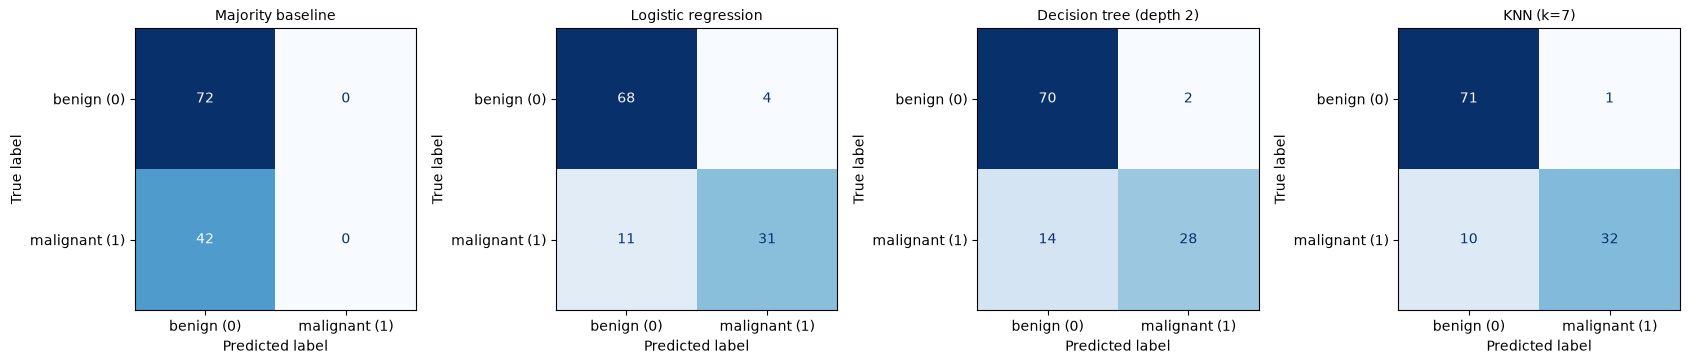

In [10]:
final_models = {
    'Majority baseline': DummyClassifier(strategy='most_frequent'),
    'Logistic regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    'Decision tree (depth 2)': DecisionTreeClassifier(max_depth=2, random_state=RANDOM_STATE),
    f'KNN (k={best_k})': make_knn(best_k),
}
test_results = []
test_predictions = {}
for name, model in final_models.items():
    model.fit(X_train_val, y_train_val)
    test_results.append(summarize(name, model, X_test, y_test))
    test_predictions[name] = model.predict(X_test)
    if hasattr(model, 'named_steps'):
        assert np.allclose(model.named_steps['standardscaler'].mean_, X_train_val.mean(axis=0))

fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, (name, predictions) in zip(axes, test_predictions.items()):
    matrix = confusion_matrix(y_test, predictions, labels=[0, 1])
    assert matrix.sum() == len(y_test)
    ConfusionMatrixDisplay(matrix, display_labels=CLASS_NAMES).plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(name, fontsize=10)
fig.tight_layout()
plt.show()

KNN: 32 of 42 actual malignant test rows detected; 10 missed.
1 benign rows were predicted malignant; 71 were correctly predicted benign.


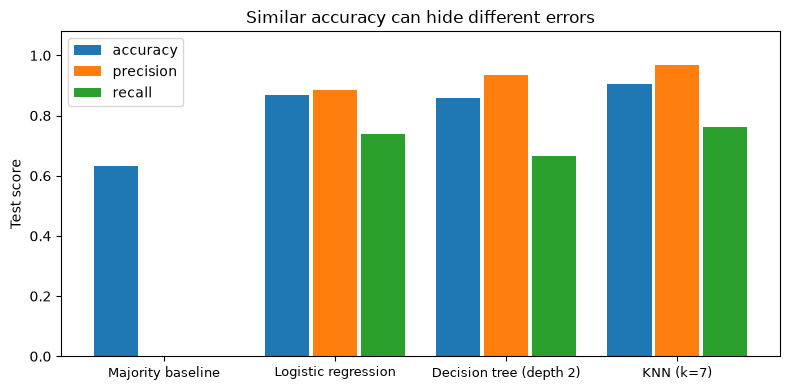

In [11]:
knn_name = f'KNN (k={best_k})'
tn, fp, fn, tp = confusion_matrix(y_test, test_predictions[knn_name], labels=[0, 1]).ravel()
print(f'KNN: {tp} of {tp + fn} actual malignant test rows detected; {fn} missed.')
print(f'{fp} benign rows were predicted malignant; {tn} were correctly predicted benign.')
fig, ax = plt.subplots(figsize=(8, 4))
positions = np.arange(len(test_results))
for offset, metric in [(-0.28, 'accuracy'), (0, 'precision'), (0.28, 'recall')]:
    ax.bar(positions + offset, [row[metric] for row in test_results], width=0.26, label=metric)
ax.set(xticks=positions, xticklabels=[row['model'] for row in test_results], ylim=(0, 1.08), ylabel='Test score', title='Similar accuracy can hide different errors')
ax.tick_params(axis='x', labelsize=9)
ax.legend()
fig.tight_layout()
plt.show()

## 7. Practice explaining results like an analyst

Use your actual outputs to complete these statements:

1. **Model selection:** "We chose k = ___ because its validation accuracy was ___. We did not use test rows to choose it."
2. **One prediction:** "The inspected row had ___ class-1 neighbors out of ___. The model predicted ___; its actual label was ___."
3. **Errors:** "KNN missed ___ of ___ actual malignant test rows. Its recall was ___. This means ___."
4. **Comparison:** "Compared with logistic regression and the tree, KNN had ___ false negatives and ___ false positives. Accuracy alone does / does not tell the full story because ___."
5. **Limitations:** "These results use only two features, one split, and a historical dataset. They do not establish ___."

### Extension practice (validation only)

- Compare a raw-feature KNN with a scaled KNN at the same k. Which neighbors change? Do not assume scaling must improve every score.
- Compare `weights='uniform'` with `weights='distance'`. The nearer neighbors then receive more weight; the vote fraction is no longer a simple count divided by k.
- Plot k = 1 and k = 51 boundaries beside the selected model. Explain noise sensitivity and excessive smoothing.
- Discuss why arbitrary numerical category codes are not meaningful Euclidean distances, and why many irrelevant features can hurt KNN.

**Do not repeatedly inspect the test scores to optimize these extensions.** After examining the test output, it is no longer an untouched source for additional decisions. A new final evaluation would need fresh held-out data.

### Further cautions

KNN retains training examples, which requires memory and careful data handling in real projects. Large datasets can make prediction expensive. Odd k does not eliminate equal-distance cutoff ties; ordering can matter for tied neighbors with different labels. Neighbor fractions are not automatically calibrated probabilities, and proximity is not causation.

### Official references

- [Iris dataset: measurements and species](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_iris.html)
- [KNeighborsClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html)
- [Nearest-neighbors user guide](https://scikit-learn.org/stable/modules/neighbors.html)
- [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html)
- [Common pitfalls: leakage and pipelines](https://scikit-learn.org/stable/common_pitfalls.html)
- [Breast-cancer dataset documentation](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html)
- [SimpleImputer](https://scikit-learn.org/stable/modules/generated/sklearn.impute.SimpleImputer.html)